In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, mutual_info_regression

In [3]:
df=pd.read_csv("House_price.csv")

In [4]:
print("Shape:",df.shape)
print(df.head())
print(df.info())

Shape: (1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0  

In [5]:
missing=pd.DataFrame({
    "Missing Values":df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})

In [6]:
missing=missing[missing["Missing Values"]>0]
missing=missing.sort_values(by="Percentage",ascending=False)
print(missing)

              Missing Values  Percentage
PoolQC                  1453   99.520548
MiscFeature             1406   96.301370
Alley                   1369   93.767123
Fence                   1179   80.753425
MasVnrType               872   59.726027
FireplaceQu              690   47.260274
LotFrontage              259   17.739726
GarageType                81    5.547945
GarageYrBlt               81    5.547945
GarageFinish              81    5.547945
GarageQual                81    5.547945
GarageCond                81    5.547945
BsmtExposure              38    2.602740
BsmtFinType2              38    2.602740
BsmtQual                  37    2.534247
BsmtCond                  37    2.534247
BsmtFinType1              37    2.534247
MasVnrArea                 8    0.547945
Electrical                 1    0.068493


In [7]:
print("Duplicate Rows:",df.duplicated().sum())

Duplicate Rows: 0


In [8]:
num_features=df.select_dtypes(include=np.number).columns
cat_features=df.select_dtypes(exclude=np.number).columns

print("Numerical Features:",len(num_features))
print("Categorical Features:",len(cat_features))

Numerical Features: 38
Categorical Features: 43


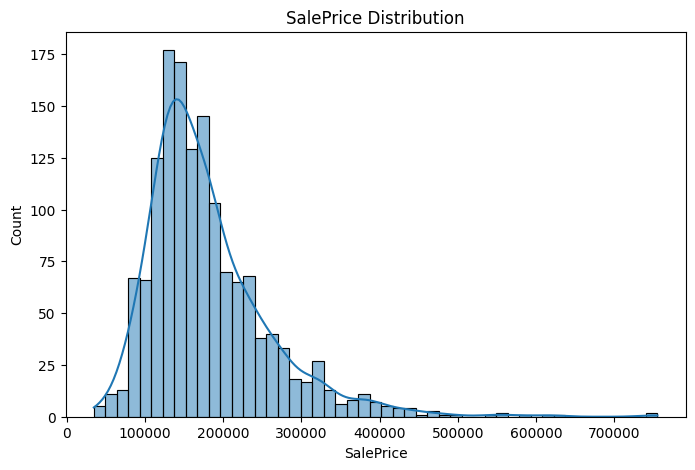

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(df["SalePrice"],kde=True)
plt.title("SalePrice Distribution")
plt.show()

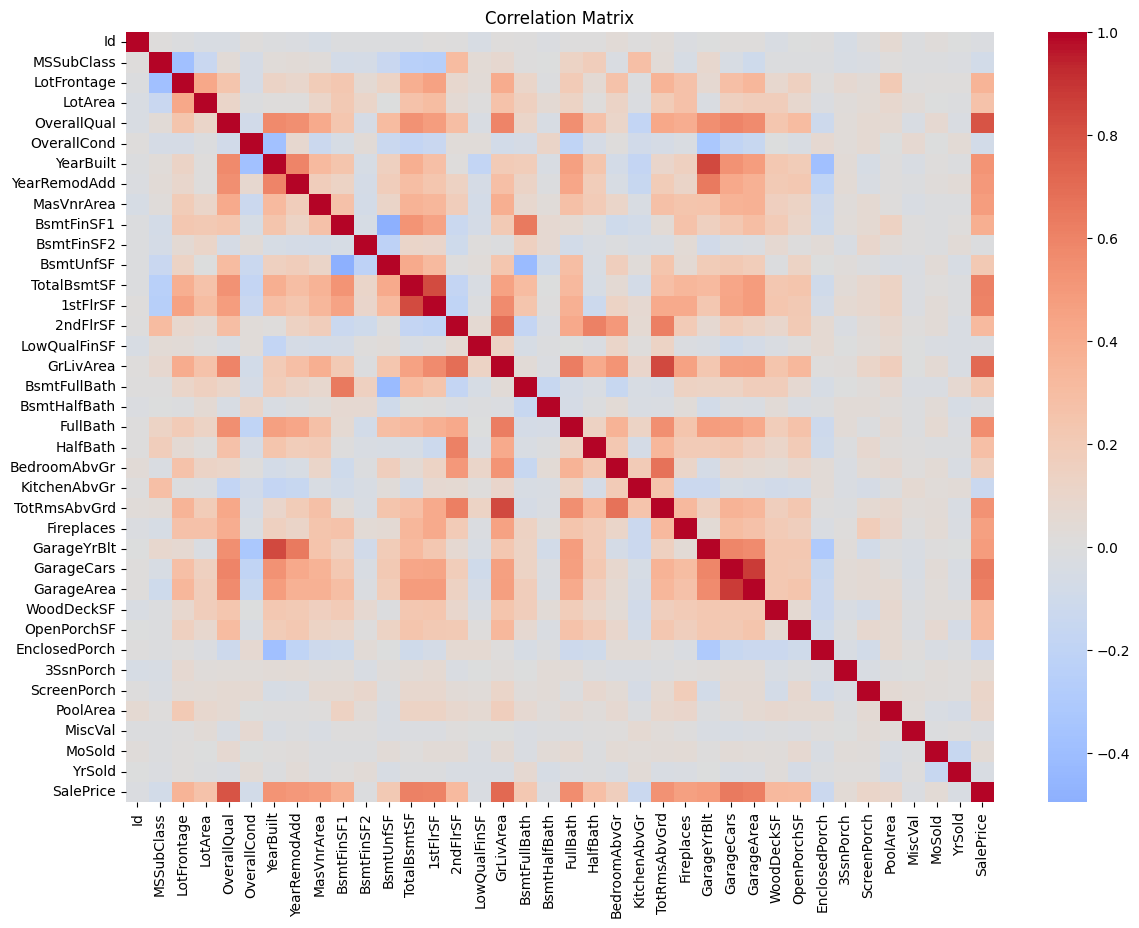

In [10]:
plt.figure(figsize=(14,10))
corr=df[num_features].corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0)
plt.title("Correlation Matrix")
plt.show()

In [13]:
skewness=df[num_features].apply(lambda x:skew(x.dropna()))
skewness=skewness.sort_values(ascending=False)

print(skewness.head(20))

MiscVal          24.451640
PoolArea         14.813135
LotArea          12.195142
3SsnPorch        10.293752
LowQualFinSF      9.002080
KitchenAbvGr      4.483784
BsmtFinSF2        4.250888
ScreenPorch       4.117977
BsmtHalfBath      4.099186
EnclosedPorch     3.086696
MasVnrArea        2.666326
OpenPorchSF       2.361912
LotFrontage       2.160866
SalePrice         1.880941
BsmtFinSF1        1.683771
WoodDeckSF        1.539792
TotalBsmtSF       1.522688
MSSubClass        1.406210
1stFlrSF          1.375342
GrLivArea         1.365156
dtype: float64


In [14]:
for col in num_features:
    df[col]=df[col].fillna(df[col].median())

for col in cat_features:
    df[col]=df[col].fillna(df[col].mode()[0])

In [15]:
encoder=LabelEncoder()
for col in cat_features:
    df[col]=encoder.fit_transform(df[col])

In [16]:
df["HouseAge"]=df["YrSold"]-df["YearBuilt"]
df["RemodelAge"]=df["YrSold"]-df["YearRemodAdd"]
df["TotalBathrooms"]=(
    df["FullBath"]+0.5*df["HalfBath"]+df["BsmtFullBath"]+0.5*df["BsmtHalfBath"
])

In [17]:
x=df.drop("SalePrice",axis=1)
y=df["SalePrice"]

In [19]:
scaler=StandardScaler()

X_scaled=scaler.fit_transform(x)

In [21]:
selector=SelectKBest(score_func=mutual_info_regression, k=20)
X_selected = selector.fit_transform(X_scaled, y)
selected_features = x.columns[selector.get_support()]

print("\nTop Selected Features:")
print(selected_features)


Top Selected Features:
Index(['MSSubClass', 'LotFrontage', 'Neighborhood', 'OverallQual', 'YearBuilt',
       'YearRemodAdd', 'ExterQual', 'BsmtQual', 'TotalBsmtSF', '1stFlrSF',
       'GrLivArea', 'FullBath', 'KitchenQual', 'GarageYrBlt', 'GarageFinish',
       'GarageCars', 'GarageArea', 'HouseAge', 'RemodelAge', 'TotalBathrooms'],
      dtype='object')
